# 04 — Dataset Preparation

Converts an explored dataset (`01`) into a flat YOLO-format training set: `images/{train,val}/`, `labels/{train,val}/`, `dataset.yaml`, `manifest.json`. Uses each dataset's `prepare_dataset()` (`aquatrack.datasets.brackishmot` / `.sfishtrack`) — publishes via hardlink by default (fast, no data duplication; falls back to copy automatically if hardlinking isn't possible, e.g. across drives).

**Kernel:** **AquaTrack+ (.venv)**.

## Configuration

In [43]:
# --- Edit for your dataset, then Run All -------------------------------
DATASET_PATH = r"C:\Users\oyele\Downloads\SFISHTRACK\SFISHTRACK"
DATASET_KIND = "sfishtrack"  # "sfishtrack" or "brackishmot"
# Same drive as DATASET_PATH on purpose -- os.link() (hardlink) cannot
# cross Windows drive letters, and this dataset's images total ~26 GB.
# Across drives that silently falls back to a real byte-for-byte copy of
# all ~23K images (confirmed: this is what timed out the first attempt at
# a D:-based OUTPUT_PATH here, taking well over 5 minutes and still not
# done). Same-drive hardlinking is near-instant and uses no extra disk space.
OUTPUT_PATH = r"C:\Users\oyele\AquaTrack_data\sfishtrack_yolo"
VALIDATION_FRACTION = 0.2
SEED = 42
PUBLISH_METHOD = "hardlink"  # "hardlink" or "copy" -- see the OUTPUT_PATH note above
# ------------------------------------------------------------------------

In [44]:
from pathlib import Path
import shutil

dataset_path = Path(DATASET_PATH)
output_path = Path(OUTPUT_PATH)
manifest_path = output_path / "manifest.json"
assert dataset_path.is_dir(), f"DATASET_PATH does not exist: {dataset_path}"
assert DATASET_KIND in ("sfishtrack", "brackishmot"), (
    f"04 has a specialized preparer for sfishtrack/brackishmot only, got {DATASET_KIND!r}"
)

# manifest.json is written last by prepare_dataset(), after every image/label
# is on disk -- checking for *it* specifically (not just "directory has some
# content") avoids mistaking a still-in-progress run for a completed one.
if manifest_path.is_file():
    print(f"OUTPUT_PATH already has a completed manifest: {output_path}")
    print("Re-running prepare_dataset requires an empty directory -- "
          "delete it first if you want to regenerate (uncomment below).")
    # shutil.rmtree(output_path)
elif output_path.exists() and any(output_path.iterdir()):
    raise RuntimeError(
        f"{output_path} has content but no manifest.json -- likely a previous "
        "prepare_dataset() run that didn't finish (interrupted, or still running "
        "elsewhere). Wait for it to finish, or delete the directory and re-run."
    )
else:
    print(f"Preparing {DATASET_KIND!r} -> {output_path}")

OUTPUT_PATH already has a completed manifest: C:\Users\oyele\AquaTrack_data\sfishtrack_yolo
Re-running prepare_dataset requires an empty directory -- delete it first if you want to regenerate (uncomment below).


## Prepare

In [45]:
if DATASET_KIND == "sfishtrack":
    from aquatrack.datasets.sfishtrack import prepare_dataset
else:
    from aquatrack.datasets.brackishmot import prepare_dataset

if manifest_path.is_file():
    import json
    report = json.loads(manifest_path.read_text(encoding="utf-8"))
    # JSON object keys are always strings -- prepare_dataset() itself returns
    # class_names/classes with int keys, but round-tripping through
    # manifest.json turns them into "0", "1", ... Normalize back to int so
    # every cell below behaves the same whether report came from a fresh run
    # or a loaded manifest.
    report["class_names"] = {int(k): v for k, v in report["class_names"].items()}
    for stats in report["splits"].values():
        stats["classes"] = {int(k): v for k, v in stats.get("classes", {}).items()}
    print("Loaded existing manifest instead of re-running prepare_dataset.")
else:
    report = prepare_dataset(
        dataset_path, output_path,
        validation_fraction=VALIDATION_FRACTION, seed=SEED, method=PUBLISH_METHOD,
    )
print("class_names:", report["class_names"])

Loaded existing manifest instead of re-running prepare_dataset.
class_names: {0: 'fish'}


## Split summary

In [46]:
import pandas as pd

summary_rows = [
    {"split": split, **{k: v for k, v in stats.items()
                        if k not in ("video_names", "sequence_names", "publish_methods", "classes")}}
    for split, stats in report["splits"].items()
]
pd.DataFrame(summary_rows)

,split,videos,images,annotations,skipped_boxes,low_fill_ratio_boxes,missing_frames
0,train,43,19445,102033,1247,16011,141
1,val,11,3922,23748,384,3803,24
2,test,0,0,0,0,0,0


## Class distribution per split

In [47]:
class_rows = []
for split, stats in report["splits"].items():
    for class_index, count in stats.get("classes", {}).items():
        class_rows.append({
            "split": split,
            "class": report["class_names"][int(class_index)],
            "count": count,
        })
class_df = pd.DataFrame(class_rows)
class_df

,split,class,count
0,train,fish,102033
1,val,fish,23748


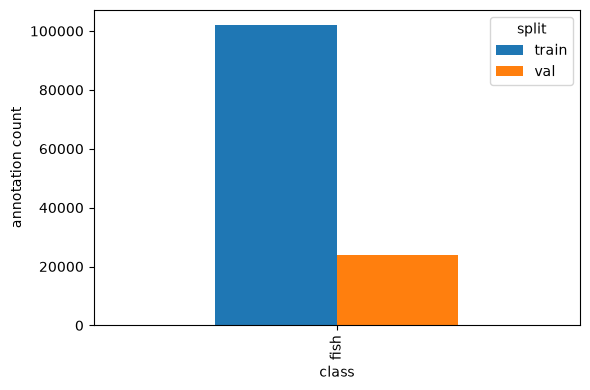

In [48]:
import matplotlib.pyplot as plt

if not class_df.empty:
    class_df.pivot(index="class", columns="split", values="count").plot.bar(figsize=(6, 4))
    plt.ylabel("annotation count")
    plt.tight_layout()
    plt.show()

## Visual sanity check

The actual point of this section: prove the YOLO label conversion is correct by drawing the written label file's boxes back onto its image and looking at it — not just trusting that `prepare_dataset` ran without raising.

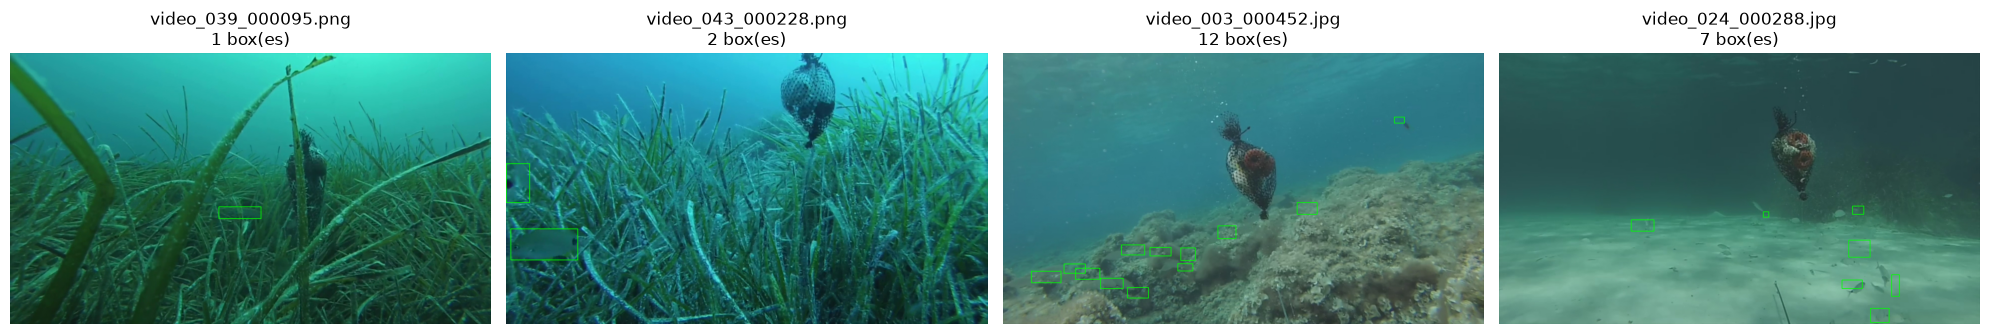

In [49]:
import cv2
import matplotlib.pyplot as plt
import random

train_images_dir = output_path / "images" / "train"
train_labels_dir = output_path / "labels" / "train"
image_paths = sorted(train_images_dir.glob("*.*"))

rng = random.Random(0)
sample_paths = rng.sample(image_paths, min(4, len(image_paths)))

fig, axes = plt.subplots(1, len(sample_paths), figsize=(5 * len(sample_paths), 5))
axes = axes if len(sample_paths) > 1 else [axes]
for ax, image_path in zip(axes, sample_paths):
    image = cv2.imread(str(image_path))
    height, width = image.shape[:2]
    label_path = train_labels_dir / f"{image_path.stem}.txt"
    box_count = 0
    for line in label_path.read_text(encoding="utf-8").splitlines():
        if not line.strip():
            continue
        class_index, cx, cy, w, h = (float(v) for v in line.split())
        x1 = int((cx - w / 2) * width)
        y1 = int((cy - h / 2) * height)
        x2 = int((cx + w / 2) * width)
        y2 = int((cy + h / 2) * height)
        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
        box_count += 1
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{image_path.name}\n{box_count} box(es)")
    ax.axis("off")
plt.tight_layout()
plt.show()

## dataset.yaml (what notebook 05 will point YOLO at)

In [50]:
print((output_path / "dataset.yaml").read_text(encoding="utf-8"))

path: C:/Users/oyele/AquaTrack_data/sfishtrack_yolo
train: images/train
val: images/val
test: images/test
names:
  0: fish

